In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("ai_jobs_salaries_clean.csv")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 71913 entries, 0 to 71912
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   work_year               71913 non-null  int64
 1   experience_level        71913 non-null  str  
 2   employment_type         71913 non-null  str  
 3   job_title               71913 non-null  str  
 4   salary                  71913 non-null  int64
 5   salary_currency         71913 non-null  str  
 6   salary_in_usd           71913 non-null  int64
 7   employee_residence      71913 non-null  str  
 8   remote_ratio            71913 non-null  int64
 9   company_location        71913 non-null  str  
 10  company_size            71913 non-null  str  
 11  experience_level_label  71913 non-null  str  
 12  employment_type_label   71913 non-null  str  
 13  work_mode               71913 non-null  str  
 14  salary_outlier_flag     71913 non-null  bool 
 15  role_family             71913 

In [5]:
df.head(15)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN
5,2025,MI,FT,Engineer,140000,USD,140000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN
6,2025,SE,FT,AI Product Lead,175000,USD,175000,US,100,US,M,Senior-level,Full-time,Remote,False,Other / Unclassified,NaN
7,2025,SE,FT,AI Product Lead,152900,USD,152900,US,100,US,M,Senior-level,Full-time,Remote,False,Other / Unclassified,NaN
8,2025,SE,FT,AI Engineer,97900,USD,97900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers
9,2025,SE,FT,AI Engineer,89900,USD,89900,US,100,US,M,Senior-level,Full-time,Remote,False,AI Engineer,Software and applications developers


In [6]:
df["company_size"].unique()

<ArrowStringArray>
['M', 'L', 'S']
Length: 3, dtype: str

In [7]:
df['salary_in_usd'].sort_values(ascending =True)

69934     15000
71417     15000
71213     15000
68966     15000
50079     15107
          ...  
65151    774000
35589    793136
64828    800000
29167    800000
18840    800000
Name: salary_in_usd, Length: 71913, dtype: int64

In [8]:
df.loc[df['experience_level'].str.contains("EX", case=False, na=False), 'experience_level'] = "Executive"

In [9]:
df.loc[df['experience_level'].str.contains("SE", case=False, na=False), 'experience_level'] = "Senior"

In [10]:
df.loc[df['experience_level'].str.contains("MI", case=False, na=False), 'experience_level'] = "Mid"

In [11]:
df.loc[df['experience_level'] == "EN", 'experience_level'] = "Entry"

In [12]:
df.loc[df['employment_type'].str.contains("FT", case=False, na=False), 'employment_type'] = "Full Time"

In [13]:
df.loc[df['employment_type'].str.contains("CT", case=False, na=False), 'employment_type'] = "Contract"

In [14]:
df.loc[df['employment_type'].str.contains("FL", case=False, na=False), 'employment_type'] = "Freelance"

In [15]:
df.loc[df['employment_type'].str.contains("PT", case=False, na=False), 'employment_type'] = "Part Time"

In [16]:
df.loc[df['company_size'].str.contains("M", case=False, na=False), 'company_size'] = "Medium"

In [17]:
df.loc[df['company_size'].str.contains("S", case=False, na=False), 'company_size'] = "Small"

In [18]:
df.loc[df['company_size'] == 'L', 'company_size'] = "Large"

In [19]:
df = df.drop("experience_level_label", axis=1)

In [20]:
df = df.drop("employment_type_label", axis=1)

In [21]:
df["isco_group_hint"].unique()

<ArrowStringArray>
['Information and communications technology service managers',
                'Mathematicians, actuaries and statisticians',
                                                          nan,
                       'Software and applications developers',
              'Business services and administration managers',
                   'Physical and earth science professionals']
Length: 6, dtype: str

In [22]:
df.loc[df['isco_group_hint'].isna() , 'isco_group_hint'] = "Unclassified"

In [23]:
df.loc[df['isco_group_hint']== "Unclasified" , 'isco_group_hint'] = "Unclassified"

In [24]:
df['role_family'].unique()

<ArrowStringArray>
[   'Analytics Manager',       'Data Scientist', 'Other / Unclassified',
          'AI Engineer',         'Data Analyst',      'Computer Vision',
        'Data Engineer',          'ML Engineer',   'Research Scientist',
         'AI Architect',                  'NLP']
Length: 11, dtype: str

In [25]:
unclassified_family = df.loc[df['role_family'].str.contains('Other / Unclassified', case=False, na=False)]

In [26]:
print(unclassified_family)

       work_year experience_level employment_type  \
4           2025              Mid       Full Time   
5           2025              Mid       Full Time   
6           2025           Senior       Full Time   
7           2025           Senior       Full Time   
12          2025           Senior       Full Time   
...          ...              ...             ...   
71842       2021           Senior       Full Time   
71862       2020            Entry       Full Time   
71888       2021            Entry       Full Time   
71905       2021              Mid       Full Time   
71907       2021           Senior       Full Time   

                                job_title   salary salary_currency  \
4                                Engineer   160000             USD   
5                                Engineer   140000             USD   
6                         AI Product Lead   175000             USD   
7                         AI Product Lead   152900             USD   
12           

In [27]:
# 1. Store the unique titles in a variable
unclassified_titles = df[df['role_family'] == 'Other / Unclassified']['job_title'].unique()

# 2. Print the unique titles
print(unclassified_titles)

<ArrowStringArray>
[                          'Engineer',                    'AI Product Lead',
                            'Manager',                    'Data Management',
                    'Product Manager',                  'Software Engineer',
                          'Developer',                          'Associate',
            'Computational Scientist',                            'Analyst',
 ...
 'Applied Machine Learning Scientist',      'Analytics Engineering Manager',
                 'AWS Data Architect',      'Autonomous Vehicle Technician',
           'Deep Learning Researcher',                 'Big Data Architect',
             'Data Science Tech Lead',           'Principal Data Architect',
            'Data Analytics Engineer',               'Cloud Data Architect']
Length: 333, dtype: str


In [28]:
import numpy as np

# 1. Create the mask for unclassified rows
unclassified_mask = df['role_family'] == 'Other / Unclassified'

# 2. FILTER
unclassified_titles = df.loc[unclassified_mask, 'job_title'].astype(str).str.lower()

# 3. Define conditions on the filtered titles series
conditions = [
    unclassified_titles.str.contains(r'\bnlp\b|natural language|text processing|llm|large language|langchain', na=False),
    unclassified_titles.str.contains(r'architect', na=False),
    unclassified_titles.str.contains(r'research|scientist|computational|statistician|statistical programmer', na=False),
    unclassified_titles.str.contains(r'deep learning|machine learning|modeler', na=False),
    unclassified_titles.str.contains(r'analytics engineer|data engineer|big data| data management|data specialist|data management specialist', na=False),
    unclassified_titles.str.contains(r'analyst|analytics', na=False),
    unclassified_titles.str.contains(r'manager|lead|product manager|head|director|governance specialist|data strategist|product designer|governance', na=False),
    unclassified_titles.str.contains(r'software|developer|engineer|AI specialist', na=False)
]

choices = [
    'NLP',
    'Data Architect',
    'Research Scientist',
    'ML Engineer',
    'Data Engineer',
    'Data Analyst',
    'Analytics Manager',
    'AI Engineer'
]

# 4. Assign the matched results directly (lengths now match perfectly)
df.loc[unclassified_mask, 'role_family'] = np.select(
    conditions, 
    choices, 
    default='Other / Unclassified'
)

In [29]:
# Check new value counts for role_family
print(df['role_family'].value_counts())

role_family
AI Engineer             16954
Data Analyst            13199
Data Engineer            9523
Analytics Manager        9209
Data Scientist           7216
Research Scientist       5042
ML Engineer              4037
Other / Unclassified     3760
Data Architect           2594
AI Architect              219
Computer Vision           140
NLP                        20
Name: count, dtype: int64


In [30]:
df[df['role_family'] == 'Other / Unclassified']['job_title'].value_counts().head(15)

job_title
Associate                        1238
Consultant                        783
Data Product Owner                132
Product Owner                     115
Data Management                   102
AI Specialist                      86
Executive                          72
Member of Technical Staff          70
Account Executive                  64
Data Integration Specialist        60
Data Visualization Specialist      59
Data Analysis                      53
Postdoctoral Fellow                53
Data Operations Specialist         50
Bioinformatician                   48
Name: count, dtype: int64

VISUALIZATIONS USING MATPLOTLIB AND SEABORN

In [31]:
df_clean = df[df['role_family'] != 'Other / Unclassified'].copy()


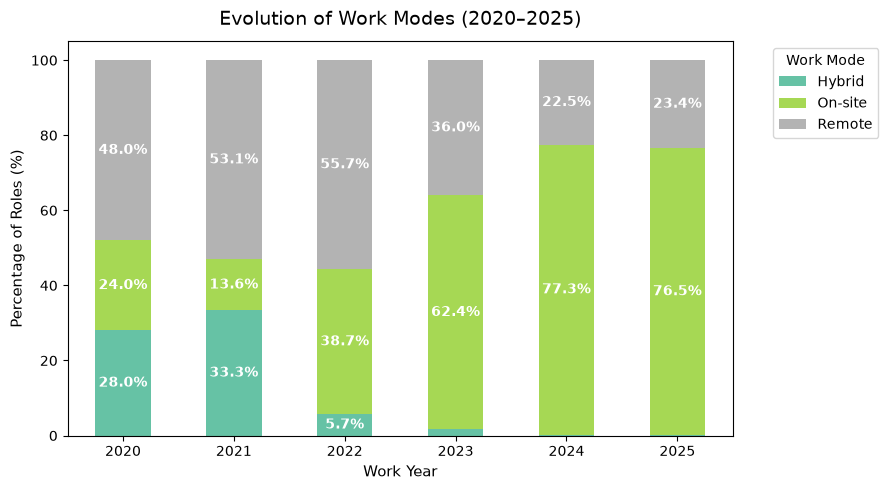

In [32]:
# Create a cross-tabulation of proportions per year
work_mode_props = pd.crosstab(df_clean['work_year'], df_clean['work_mode'], normalize='index') * 100

# Plot 100% stacked bar chart
ax = work_mode_props.plot(
    kind='bar', 
    stacked=True, 
    figsize=(9, 5), 
    colormap='Set2'
)

plt.title('Evolution of Work Modes (2020–2025)', fontsize=14, pad=12)
plt.xlabel('Work Year', fontsize=11)
plt.ylabel('Percentage of Roles (%)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(title='Work Mode', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add percentage annotations inside bars
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:  # Only annotate segments larger than 5%
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f'{height:.1f}%', ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

INSIGHTS:

Remote work peaked in 2022 at 55.7% of all job listings. However, between 2023 and 2024, the market underwent an aggressive structural reversal, with On-site roles surging from 38.7% in 2022 to 77.3% in 2024, stabilizing at 76.5% in 2025.
Hybrid working arrangements held a strong presence early on (peaking at 33.3% in 2021). By 2023, hybrid crashed to 1.6% (visible as the sliver above the 62.4% on-site bar) and effectively dropped to negligible fractions by 2024–2025.

RECOMMENDATIONS:

Maintain a targeted 20–25% remote allocation exclusively reserved for hard-to-fill, high-tier roles (like senior AI Architects and principal ML Engineers).

Eliminate ambiguous "2-days-a-week" hybrid policies. Clearly define roles during headcount planning as either strictly On-site (for collaborative product/hardware teams) or Fully Remote (for specialized individual contributors).

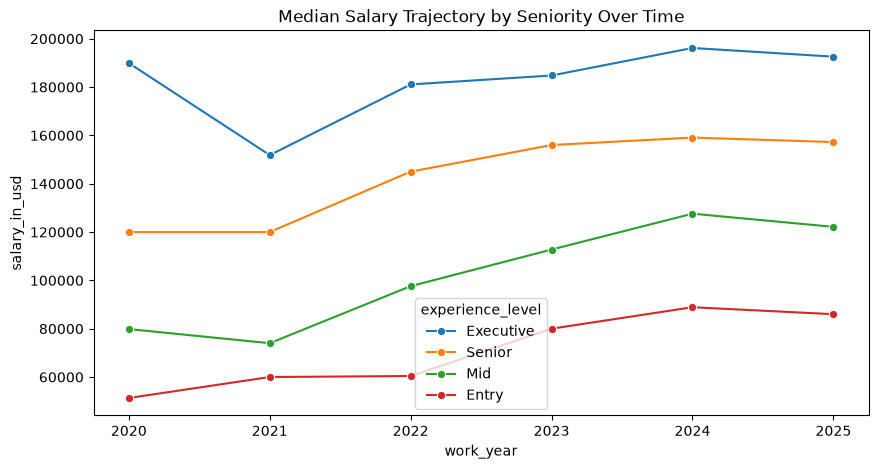

In [33]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_clean, 
    x='work_year', 
    y='salary_in_usd', 
    hue='experience_level',
    estimator='median',
    errorbar=None,
    marker='o'
)
plt.title('Median Salary Trajectory by Seniority Over Time')
plt.show()

INSIGHTS:

Salary generally increased over the period.

Salary growth was uneven across levels with notable declines for the Executive and Mid-level positions in 2021. 2022-2024 appear to have been the strongest grwoth periods across all experience levels with 2024 peaking.

RECOMMENDATIONS:

The declines in 2021 and 2025 shows that salary rates change considerably. Companies should review their compensation rates regularly to ensure that they remain competitive and in alignement to market conditions.

Since Entry-level salaries have the highest increase, employers should benchmark these positions to secure emerging talent especially to competitve roles.

The 2025 decline should be investigated for changes in the labour market, inflated-adjusted pay or even the company compsiition.



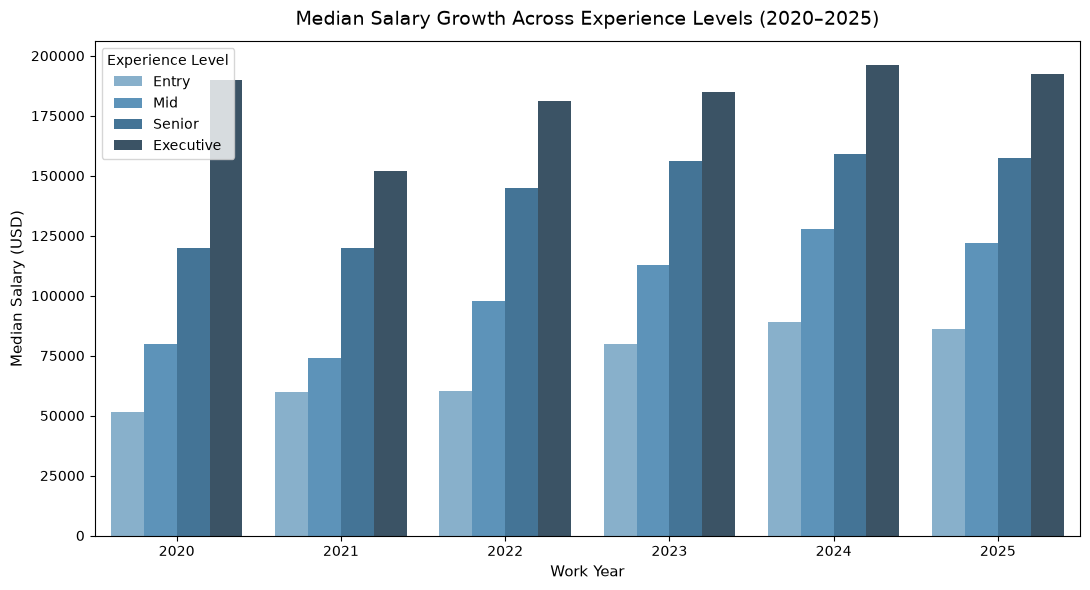

In [34]:
plt.figure(figsize=(11, 6))

# Define chronological order
exp_order = ['Entry', 'Mid', 'Senior', 'Executive']

# Aggregate median salary
exp_trend = df_clean.groupby(['work_year', 'experience_level'])['salary_in_usd'].median().reset_index()

# Plot grouped bars
sns.barplot(
    data=exp_trend, 
    x='work_year', 
    y='salary_in_usd', 
    hue='experience_level', 
    hue_order=exp_order, 
    palette='Blues_d'
)

plt.title('Median Salary Growth Across Experience Levels (2020–2025)', fontsize=14, pad=12)
plt.xlabel('Work Year', fontsize=11)
plt.ylabel('Median Salary (USD)', fontsize=11)
plt.legend(title='Experience Level')
plt.tight_layout()
plt.show()

INSIGHTS:

While the pay delta between Entry and Mid-level roles increases linearly, there is a pronounced 'jump'  in compensations when moving from Mid to Senior and Executive levels across all years.

Executive level median salaries experienced agressive expansion in early years(2020 - 2022), but show relative stabilization in recent years.

RECOMMENDATIONS:

Rather than competing in the expensive external market, invest in structured mentorship and technical leadership programs to promote high-performing mid-level talent internally.

Cap base cash salaries for Executive roles near the Senior market threshold, shifting top-end compensation into performance-contingent equity or revenue share bonusing.

In [35]:
df[df['company_location'] == "NZ" ]['role_family'].value_counts


<bound method IndexOpsMixin.value_counts of 4602       Data Analyst
4603       Data Analyst
4604       Data Analyst
4605       Data Analyst
5069       Data Analyst
              ...      
65002    Data Architect
65393      Data Analyst
66215    Data Scientist
66216    Data Scientist
71825     Data Engineer
Name: role_family, Length: 69, dtype: str>

In [36]:
df[df['role_family'] == 'Analytics Manager']['employee_residence'].value_counts() 

employee_residence
US    7954
CA     529
GB     415
AU      46
NL      29
LT      24
IE      24
DE      18
ES      17
AT      14
FR      14
FI      11
SK      10
IN       9
MX       7
ZA       6
CO       6
SG       5
PT       5
BR       5
PL       5
NZ       4
JP       4
CR       4
CL       4
BE       3
CH       3
LV       2
SI       2
LS       2
PH       2
LB       2
EG       2
EC       2
SV       2
KE       2
TR       2
IL       2
AM       2
CZ       1
AE       1
ID       1
DK       1
AR       1
PK       1
RO       1
MY       1
EE       1
RU       1
Name: count, dtype: int64

In [37]:
df.groupby(['role_family', 'company_location'])['salary_in_usd'].median().loc['Analytics Manager'].sort_values()

company_location
AR     24000.0
AS     27000.0
EE     31520.0
LV     36631.0
ZA     39116.5
SK     40666.0
SV     42000.0
EC     42000.0
PH     43288.0
CR     45000.0
AT     47670.5
CZ     50526.0
MX     54000.0
CL     54000.0
RO     56000.0
AM     56100.0
CO     56500.0
ES     61066.5
ID     63774.0
KE     64500.0
LT     65262.5
PL     66000.0
FR     68421.0
PK     70000.0
BE     73333.0
PT     75000.0
LS     75657.5
NL     76610.0
SI     77735.0
JP     80883.0
GB     88607.0
DK     95588.0
IN     98200.0
FI     98400.0
AE    100000.0
DE    103444.5
BR    107997.0
CH    113636.0
SG    118000.0
IL    122010.0
TR    122010.0
EG    123800.0
AU    131745.5
CA    138000.0
IE    146494.0
LB    166250.0
US    169000.0
NZ    175881.0
RU    230000.0
Name: salary_in_usd, dtype: float64

In [38]:
df_cleaned = df_clean[df_clean['salary_in_usd'] < 500000]

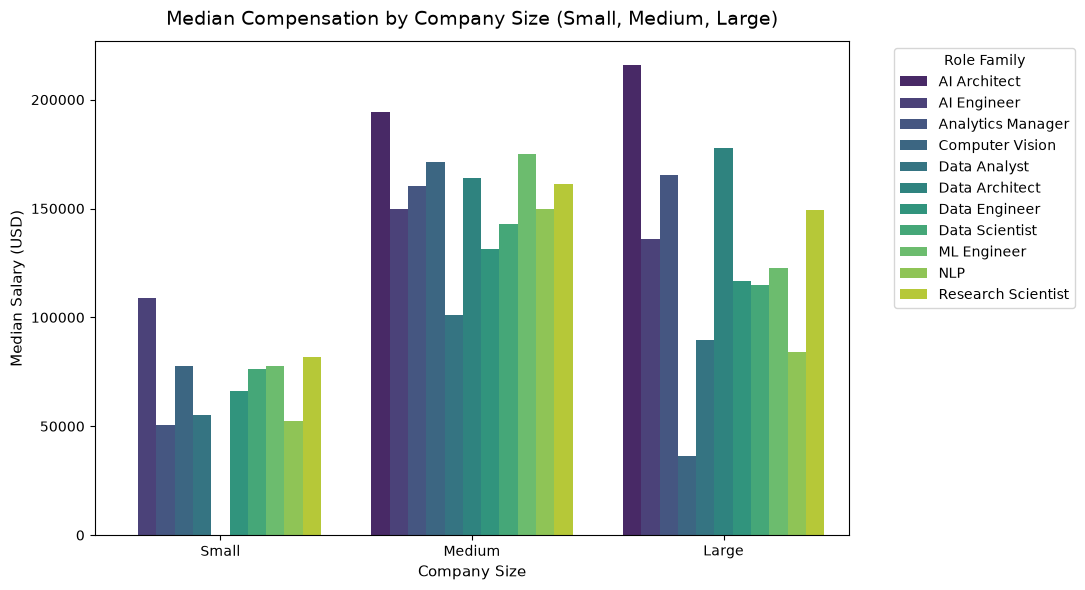

In [39]:
plt.figure(figsize=(11, 6))

# Aggregate median salary by company size and role family
size_df = df_clean.groupby(['company_size', 'role_family'])['salary_in_usd'].median().reset_index()

sns.barplot(
    data=size_df, 
    x='company_size', 
    y='salary_in_usd', 
    hue='role_family', 
    order=['Small', 'Medium', 'Large'], 
    palette='viridis'
)

plt.title('Median Compensation by Company Size (Small, Medium, Large)', fontsize=14, pad=12)
plt.xlabel('Company Size', fontsize=11)
plt.ylabel('Median Salary (USD)', fontsize=11)
plt.legend(title='Role Family', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

INSIGHTS:

AI Architects consistently represent the highest earning job families starting around $126,000 and progressing to over $200,000 at the different company sizes.
Computer Vision and Data Analysts suffer in large companies due to commoditization with pre-trained API services. Data Analysts are lacking in small companies and the prioritization of platform building roles like Data/ML/AI Engineers.

RECOMMENDATIONS

Large enterprises should stop over-specifying Computer Vision requirements, leaving routine compuer vision tasks to cloud-native APIs.By this Computer Vision roles are reserved only for proprietary high-ROI()

Data Analyst salary compression should be unstuck by repositioning the roles into Analytics Managers or Data Engineers. They should upgrade their tech stack and try AI adoption for analytics pipeline automations and increased efficiency.

Utilise multi-year equity cliffs tied to major architectural milestones like an LLM platform to align theur long-term incentives with business performance.

C:\Users\Ekemini-Abasi\AppData\Local\Temp\ipykernel_16420\1138285537.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


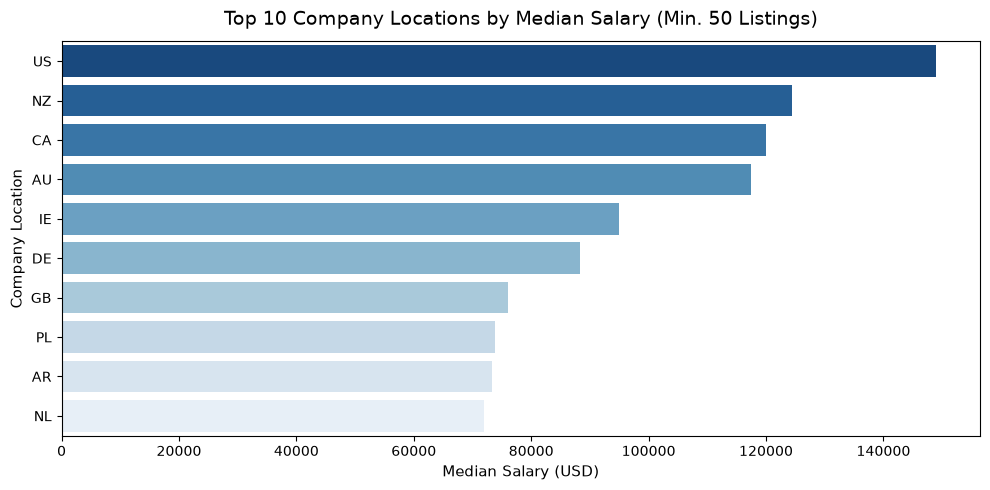

In [40]:
# Aggregate median salary and listing count by country
country_summary = df_clean.groupby('company_location').agg(
    median_salary=('salary_in_usd', 'median'),
    job_count=('salary_in_usd', 'count')
).query('job_count >= 50').sort_values(by='median_salary', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=country_summary.reset_index(), 
    x='median_salary', 
    y='company_location', 
    palette='Blues_r'
)

plt.title('Top 10 Company Locations by Median Salary (Min. 50 Listings)', fontsize=14, pad=12)
plt.xlabel('Median Salary (USD)', fontsize=11)
plt.ylabel('Company Location', fontsize=11)
plt.tight_layout()
plt.show()

INSIGHTS:

The US leads with the highest compensation/salaries of over $140K, compared to the Netherlands coming in at about $75K. This is attributed to the variance in market conditions of the countries as well as the cost of living. Beyond that, the US has a larger capital market concentration and seek hyper-specialized roles compared to New Zealand which also typically requires its tech professonals to be generalists. Another factor worthy of note is the exchange rate volatility. The USD is the baseline making it immune to currency conversions so when local salaries get converted to USD they lose nominal ground.

RECOMMENDATIONS:

Adopt Localized Total Rewards: Avoid applying a single global USD compensation scale across all markets. Instead, anchor base salaries to the top 10–15% of the local target country's market rate while supplementing with performance bonuses or equity to stay highly competitive locally.

Set country-specific salary ceilings (e.g., capping Mid/Senior engineering offers in European hubs at a specific percentage relative to US baselines) to maintain gross margins while scaling global headcount.

In [41]:
import matplotlib.patches as patches

kpi_data = [
    {"filename": "kpi_1_records.png", "title": "TOTAL RECORDS", "value": "71,913", "sub": "2020–2025 Market Scope", "color": "#64748B"},
    {"filename": "kpi_2_median.png",  "title": "MEDIAN COMP", "value": "$195,000", "sub": "▲ +8.2% YoY Growth", "color": "#059669"},
    {"filename": "kpi_3_role.png",    "title": "TOP EARNING ROLE", "value": "AI Architect", "sub": "$194k–$215k Band", "color": "#2563EB"},
    {"filename": "kpi_4_onsite.png",  "title": "ON-SITE SHARE", "value": "76.5%", "sub": "Up from 38.7% (2022)", "color": "#D97706"},
    {"filename": "kpi_5_delta.png",   "title": "GEO PAY DELTA", "value": "2.8x", "sub": "US ($185k) vs NZ ($65k)", "color": "#64748B"}
]

def generate_individual_kpi_card(title, value, sub, sub_color, filename):
    # Single card figure dimensions (width: 3.5 inches, height: 2.2 inches)
    fig, ax = plt.subplots(figsize=(3.5, 2.2), facecolor='#FFFFFF')
    ax.axis('off')
    
    # Draw card outline & background
    card = patches.FancyBboxPatch(
        (0.04, 0.05), 0.92, 0.90,
        boxstyle="round,pad=0.02,rounding_size=0.08",
        ec="#CBD5E1",  # Border stroke
        fc="#F8FAFC",  # Fill color
        transform=ax.transAxes
    )
    ax.add_patch(card)
    
    # Title
    ax.text(0.5, 0.75, title.upper(), transform=ax.transAxes,
            ha='center', va='center', fontsize=10, fontweight='bold', color='#64748B')
    
    # Auto-scaling text for value
    val_str = str(value)
    val_size = 14 if len(val_str) > 12 else (17 if len(val_str) > 8 else 22)
    ax.text(0.5, 0.48, val_str, transform=ax.transAxes,
            ha='center', va='center', fontsize=val_size, fontweight='bold', color='#0F172A')
    
    # Subtitle / Trend
    ax.text(0.5, 0.22, sub, transform=ax.transAxes,
            ha='center', va='center', fontsize=8.5, fontweight='medium', color=sub_color)
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.close()

# Run loop to generate 5 separate image files
for kpi in kpi_data:
    generate_individual_kpi_card(
        title=kpi["title"],
        value=kpi["value"],
        sub=kpi["sub"],
        sub_color=kpi["color"],
        filename=kpi["filename"]
    )

print("Saved 5 individual KPI cards as standalone PNG files.")

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.


Saved 5 individual KPI cards as standalone PNG files.
